## **一、S3：把“看起来像图标”推进到“听懂指定要求”**

第四周的无条件模型回答“从训练分布里画一张图”，不能回答“画两个对象，并让红圆在黄方左边”。本周研究 **文本条件生成**：文本不是文件名或标签展示，而是必须影响每一步去噪预测的输入。我们的目标是建立可审查的条件链路、独立量尺与失败证据；低损失不自动等于听懂描述。

| 任务 | 本笔记交付 | 通过的真正含义 |
| --- | --- | --- |
| S3-01 | 冻结 CLIP、完整文本分段缓存、Cross-Attention | mask/条件梯度/版本正确，尚不代表可用生成 |
| S3-02 | 条件丢弃与 CFG 数学及教学参考 | 边界和分支计数通过；L04 个人代码单独验收 |
| S3-03 | 两训练种子，正确/空/打乱及单属性干预 | 分别记录损失、预测变化、生成属性收益 |
| S3-04 | 按请求评分、控制样本、盲审任务 | 无人工审核不声称正式生成评测可靠 |
| S3-05 | 验证选型、封存测试、效率账本 | 只有依赖门槛通过才打开最终测试 |
| S3-06 | Flow 二维实验、主实验预登记、B 线及研究卡 | 不提前执行图像 Flow 或 LoRA |

**学习顺序**：先跑通两种 token 的信息流 → 推导注意力和 CFG → 检查条件真的到达网络 → 看完整对照 → 用证据选择下一步。个人 VAE 代码现已通过 S1 验收；DiT、CFG、Flow 个人主体继续留给你。完整条件核心只在本 Notebook 定义，来源为 `notebook_reference`。

本地计算上限 30 分钟，不用收费资源。安装和显式下载另计。基础 CLI 仍只有 doctor 可用。预登记见 [s3.yaml](../../configs/experiments/s3.yaml)，阅读来源见 [论文导航](../papers/README.md)。

### **1. 先把整体数据流放在脑中**

**训练**：图像 $x$ → 冻结 VAE 均值编码并缩放得到 $z$；描述 $y$ → 冻结 CLIP 得到 token 矩阵 $C$ 与有效位 mask。随机抽取离散时间 $t$ 和噪声 $\epsilon$，组成 $z_t$。DiT 每层让图像 query 访问文本 key/value，输出噪声估计。与真实 $\epsilon$ 做 MSE，只更新 DiT。

**采样**：用户描述先编码一次，初始潜变量为随机噪声；每一步根据当前潜变量、时间和同一文本预测噪声，必要时组合空条件预测，再更新潜变量。迭代结束后用冻结 VAE 解码。文本编码器不是一个“替你画图”的生成器，VAE 也不负责理解文字。

| 符号/代码 | 形状 | 职责 |
| --- | --- | --- |
| $z_t$ / noisy | `[b,4,16,16]` | 被恢复的空间状态 |
| $X$ / image_tokens | `[b,64,128]` | patch=2 的图像表示 |
| $C$ / text | `[b,n,512]` | CLIP 最后层 token 表示 |
| mask | `[b,n]`，Bool | True 是有效 token，不是要丢弃的位置 |
| 时间表示 | `[b,128]` | 继续通过 adaLN-Zero 调节图像分支 |
| 预测噪声 | `[b,4,16,16]` | 与监督噪声同形 |

$n$ 可以是 77 或显式分段后的 154。它与 64 个图像 token 不需要相等；进入注意力后只有 key/query 的特征宽度需要相同。

In [1]:
import copy
import hashlib
import json
import os
import platform
import time
from pathlib import Path
from types import SimpleNamespace

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
import matplotlib.pyplot as plt
import numpy as np
import torch
import yaml
from PIL import Image, ImageFilter
from torch import nn

from minigen.autoencoders.frozen import FrozenVAE, hash_file, to_image
from minigen.conditioning.text import FrozenTextEncoder, text_cache
from minigen.data.icons import HELD, caption, load_manifest
from minigen.data.latent import CachedLatentDataset, latent_cache_identity
from minigen.evaluation.conditional import (
    paired_difference,
    score_request,
    shuffled_indices,
    summarize,
)
from minigen.objectives.ddpm_scheduler import DDPMScheduler
from minigen.samplers.conditional import sample_conditional, synchronize
from minigen.training.conditional import train_conditional
from minigen.training.denoising import TrainConfig, seed_all

CFG = yaml.safe_load((ROOT / "configs/experiments/s3.yaml").read_text())
RUN = ROOT / "artifacts/runs" / CFG["run_id"]
FIG = ROOT / "reports/stage3/figures"
RUN.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
torch.set_num_threads(4)
DEVICE = "mps" if torch.backends.mps.is_available() else "cpu"
# 真正的前向与反向检查，而不只读取 is_available。
probe = torch.ones(4, device=DEVICE, requires_grad=True)
(probe.square().sum()).backward()
assert torch.equal(probe.grad.cpu(), torch.full((4,), 2.0))
COMPUTE_START = time.monotonic()
RESULTS = {
    "date": "2026-11-05",
    "source": "notebook_reference",
    "device": DEVICE,
    "python": platform.python_version(),
    "torch": str(torch.__version__),
    "run_id": CFG["run_id"],
    "budget_seconds": CFG["budget"]["compute_seconds"],
    "paid_cost": 0,
    "config_sha256": hash_file(ROOT / "configs/experiments/s3.yaml"),
}
print({k: v for k, v in RESULTS.items() if k != "config_sha256"})

{'date': '2026-11-05', 'source': 'notebook_reference', 'device': 'mps', 'python': '3.12.14', 'torch': '2.14.1', 'run_id': 's3_conditional_v3', 'budget_seconds': 1800, 'paid_cost': 0}


## **二、文本表示：冻结的 CLIP 会什么，又不会什么**

### **1. 从对比学习到 token 条件**

CLIP（Contrastive Language–Image Pre-training）在图像和描述配对上做对比学习：同一对的整体表示要更接近，批次内其他配对要拉开。设归一化图像表示 $v_i$、文本表示 $u_j$，温度为 $\tau$，文本方向的一项交叉熵为：

$$L_i=-\log\frac{\exp(v_i^\top u_i/\tau)}{\sum_j\exp(v_i^\top u_j/\tau)}$$

这说明它被训练过区分语义配对，**不能推出它可靠理解数量、属性绑定和任意空间关系**。本项目不重训 CLIP，不运行视觉网络，也不把 CLIP 相似度当作条件成功的真值。[CLIP 原论文](https://arxiv.org/abs/2103.00020v1) 的第 2 节给出训练机制；[LDM](https://arxiv.org/abs/2112.10752v2) 第 3.3 节说明 Cross-Attention 的条件接口。

原模型会得到每个 token 的隐藏向量和用于整体检索的 pooled 表示。本项目用 **最后层 token 矩阵**，保留词序相关信息；不只取一个句向量。冻结表示仍由 DiT 的可训练投影学习如何使用，不能把“预训练”当作免除条件验证的理由。

### **2. 77 个 token、padding 与空条件**

CLIP 上下文含起始 BOS、内容和结束 EOS，总长 77，单段最多装 75 个内容 token。token 不等于英文单词；复杂词可能被拆开。若截掉描述尾部的“在左边”，训练就会把缺失条件当成正确标签。

本轮保留原始完整描述，**显式连续分段**：每段最多 75 个内容 token，各自加 BOS/EOS 和局部位置编码，再按段顺序拼接隐藏表示；最多两段，超过 150 个内容 token 就拒绝。这样保留所有输入 token，但不同段没有 CLIP 内部上下文交流，不能把它称为原版 CLIP 的 154-token 联合理解；图像 Cross-Attention 能同时看到两段。它是有限上下文下的工程选择，未来可比较精简描述或长文本编码器。

空条件用同一编码器对 `""` 编码，仍有 BOS/EOS，**不是全零向量或全 False mask**。后者会让注意力分母无有效元素。缺失的第二段全部被输出 mask 屏蔽。缓存采用 FP16 节省空间，送入 FP32 DiT 前恢复为 FP32；这不是无损压缩，所以要测量量化误差并记录 dtype。

In [2]:
text_encoder = FrozenTextEncoder.load(
    ROOT, ROOT / "configs/models/clip_text.json", DEVICE, max_chunks=CFG["text"]["max_chunks"]
)
manifest_path = ROOT / "data/manifests/synthetic_icons_week3_v1.jsonl"
records = load_manifest(manifest_path, ROOT / "data")
train_records = [r for r in records if r["split"] == "train"]
val_records = [r for r in records if r["split"] == "validation"]
# 训练与验证进入缓存；测试描述/图像均不编码，不参与选型。
features, masks, text_lookup, text_meta = text_cache(
    text_encoder, [r["caption"] for r in train_records + val_records], RUN / "text_cache"
)
empty_id = text_lookup[""]
check_texts = ["", train_records[0]["caption"], "red " * 80]
hidden, valid, lengths = text_encoder.encode(check_texts)
error = float((hidden.half().float() - hidden).abs().max())
assert valid.any(-1).all() and lengths[-1] == 80
assert all(not p.requires_grad for p in text_encoder.model.parameters())
RESULTS["text"] = {
    "revision": text_encoder.identity["revision"],
    "meta": text_meta,
    "quantization_probe_max_abs": error,
    "empty_valid_tokens": int(masks[empty_id].sum()),
    "test_encoded": False,
}
print({k: v for k, v in text_meta.items() if k != "identity"})
print("empty", int(masks[empty_id].sum()), "quantization error", error)
# 后续主要读取缓存；释放编码网络设备内存，保留 tokenizer 以编码新的干预描述。
text_encoder.model.to("cpu")
if DEVICE == "mps":
    torch.mps.empty_cache()

/Users/lucius/projects/personal/MiniGen/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1105 00:17:09.839000 40742 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 196/196 [00:00<00:00, 28343.80it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (80 > 77). Running this sequence through the model will result in indexing errors


{'payload_sha256': 'd06636a66e700d8cb841bb40ff8ecb9a3374acf7e07c708a12978befc63d5379', 'shape': [4115, 154, 512], 'max_content_tokens': 76, 'over_one_context': 270, 'bytes': 649553260}
empty 2 quantization error 0.007808685302734375


## **三、Cross-Attention：词如何改变图像 token**

### **1. 从加权平均推导到多头注意力**

图像 token $X\in\mathbb R^{b\times n_x\times d}$ 提问，文本 token $C\in\mathbb R^{b\times n_y\times d_c}$ 提供可检索内容。投影为 $Q=XW_Q$、$K=CW_K$、$V=CW_V$。一个头的宽度是 $d_h=d/H$：

$$S_{ij}=\frac{Q_i^\top K_j}{\sqrt{d_h}},\qquad A_{ij}=\frac{\exp(S_{ij})}{\sum_{k\in\mathcal V}\exp(S_{ik})},\quad j\in\mathcal V$$

$\mathcal V$ 是 mask 为 True 的文本位置，其他位置概率为零。若 $Q,K$ 各维独立且方差约 1，点积方差约 $d_h$，除以 $\sqrt{d_h}$ 把数值尺度控制在相近范围，避免一开始 softmax 过尖。每个图像位置得到文本 value 的加权和：

$$O_i=\sum_{j\in\mathcal V}A_{ij}V_j,\qquad X'=X+g\,W_O O$$

多头在不同子空间分别检索后拼接。$g$ 是可训练残差门控，不是 CFG 权重。时间条件仍控制 DiT 自注意力与 MLP 的 adaLN；文本通过新增分支注入，不把第三周原实现说成已经自带文本条件。

> **手算例**：一个 query 对两个有效 key 的缩放分数为 $(0,\log3)$，第三个位置是 padding。softmax 权重为 $(1/4,3/4,0)$。value 分别为 $(2,0)$、$(0,4)$、任意大的 padding 向量，输出仍是 $(0.5,3)$。若 padding 改变了结果，mask 实现就有问题。

### **2. 显式复用第三周核心，再增加条件分支**

下面只提取第三周唯一 `dit_reference` 源码单元并核验固定哈希，不执行第三周数据或训练。新条件模型继承教学 DiT，复用 patch、位置、时间、adaLN、输出头，只增加 Cross-Attention。个人 `src` DiT 没有被替换。

零输出头使初始噪声预测为零；零 cross gate 使新增残差起初不扰动主干。首步可能只有输出头收到梯度，随后残差门控再打开。我们应验证 **多步后文本投影梯度到达**，而不是错误要求所有参数第一步梯度均非零。

In [3]:
third = json.loads((ROOT / "docs/learning/S2_第3周_图标数据与潜空间DiT基础.ipynb").read_text())
reference_cells = [
    c for c in third["cells"] if "dit_reference" in c.get("metadata", {}).get("tags", [])
]
assert len(reference_cells) == 1
DIT_SOURCE = "".join(reference_cells[0]["source"])
DIT_HASH = hashlib.sha256(DIT_SOURCE.encode()).hexdigest()
assert DIT_HASH == "1add9941d358c3d50aef18cb6cc0f3b9dd37568befcea0499d8bc308b79a8669"
DIT_NAMESPACE = {}
exec(compile(DIT_SOURCE, "week3_dit_reference", "exec"), DIT_NAMESPACE)
TeachingDiT = DIT_NAMESPACE["TeachingDiT"]
TeachingDiTBlock = DIT_NAMESPACE["TeachingDiTBlock"]
patchify_reference = DIT_NAMESPACE["patchify_reference"]
unpatchify_reference = DIT_NAMESPACE["unpatchify_reference"]
sincos_1d = DIT_NAMESPACE["sincos_1d"]
print("reused unique teaching DiT", DIT_HASH)

reused unique teaching DiT 1add9941d358c3d50aef18cb6cc0f3b9dd37568befcea0499d8bc308b79a8669


In [4]:
class TextCrossAttentionReference(nn.Module):
    """图像 query 对文本 key/value 的多头检索；True mask 表示有效文本。"""

    def __init__(self, hidden=128, text_width=512, heads=4):
        super().__init__()
        if hidden % heads:
            raise ValueError("hidden must divide into heads")
        self.heads, self.width = heads, hidden // heads
        self.q = nn.Linear(hidden, hidden)
        self.kv = nn.Linear(text_width, hidden * 2)
        self.out = nn.Linear(hidden, hidden)

    def forward(self, image, text, mask):
        if mask.shape != text.shape[:2] or not mask.any(-1).all():
            raise ValueError("Every caption requires at least one valid token")
        b, n, d = image.shape
        q = self.q(image).reshape(b, n, self.heads, self.width).transpose(1, 2)
        k, v = (
            self.kv(text)
            .reshape(b, text.shape[1], 2, self.heads, self.width)
            .permute(2, 0, 3, 1, 4)
            .unbind(0)
        )
        logits = q @ k.transpose(-2, -1) / self.width**0.5
        logits = logits.masked_fill(~mask[:, None, None, :], -torch.finfo(logits.dtype).max)
        attended = (logits.softmax(-1) @ v).transpose(1, 2).reshape(b, n, d)
        return self.out(attended)


class ConditionalDiTReference(TeachingDiT):
    """复用唯一无条件教学 DiT，每个块后增加零门控的文本残差。"""

    def __init__(self, depth=2, hidden=128, heads=4, channels=4, size=16, patch=2, text_width=512):
        super().__init__(depth, hidden, heads, channels, size, patch)
        self.cross_norms = nn.ModuleList([nn.LayerNorm(hidden) for _ in range(depth)])
        self.cross = nn.ModuleList(
            [TextCrossAttentionReference(hidden, text_width, heads) for _ in range(depth)]
        )
        self.cross_gates = nn.Parameter(torch.zeros(depth))

    def forward(self, z, timesteps, text, mask):
        if z.shape[1:] != (self.channels, self.size, self.size) or timesteps.shape != (len(z),):
            raise ValueError("Latent/time shape mismatch")
        tokens = self.patch_projection(patchify_reference(z, self.patch)) + self.position
        time_condition = self.time_mlp(sincos_1d(timesteps, self.hidden))
        for i, block in enumerate(self.blocks):
            tokens = block(tokens, time_condition)
            tokens = tokens + self.cross_gates[i] * self.cross[i](
                self.cross_norms[i](tokens), text, mask
            )
        shift, scale = self.final_modulation(time_condition).chunk(2, dim=-1)
        output = self.output(TeachingDiTBlock.modulate(self.final_norm(tokens), shift, scale))
        return unpatchify_reference(output, self.channels, self.size, self.size, self.patch)

In [5]:
# 手算 softmax 与 padding 不变性；独立数值，不只是同一函数再调一次。
scores = torch.tensor([0.0, np.log(3.0), 100.0])
scores[2] = -torch.inf
weights = scores.softmax(-1)
assert torch.allclose(weights, torch.tensor([0.25, 0.75, 0.0], dtype=weights.dtype))
assert torch.allclose(
    weights @ torch.tensor([[2.0, 0.0], [0.0, 4.0], [999.0, 999.0]], dtype=weights.dtype),
    torch.tensor([0.5, 3.0], dtype=weights.dtype),
)
seed_all(13)
attention = TextCrossAttentionReference(hidden=8, text_width=6, heads=2)
x = torch.randn(2, 3, 8)
c = torch.randn(2, 5, 6)
m = torch.tensor([[1, 1, 1, 0, 0], [1, 1, 0, 0, 0]], dtype=torch.bool)
changed = c.clone()
changed[~m] += 1000
assert torch.allclose(attention(x, c, m), attention(x, changed, m), atol=1e-6)
small = ConditionalDiTReference(depth=1, hidden=16, heads=2, size=4, text_width=6)
z, times = torch.randn(2, 4, 4, 4), torch.tensor([10, 20])
assert torch.count_nonzero(small(z, times, c, m)) == 0
optimizer = torch.optim.AdamW(small.parameters(), lr=0.01)
for _ in range(5):
    optimizer.zero_grad()
    (small(z, times, c, m) - z).square().mean().backward()
    optimizer.step()
assert small.cross[0].kv.weight.grad.abs().sum() > 0
RESULTS["math"] = {
    "attention_hand_example": weights.tolist(),
    "padding_invariant": True,
    "initial_output_zero": True,
    "text_projection_gradient_after_5_updates": float(small.cross[0].kv.weight.grad.norm()),
}
print(RESULTS["math"])

{'attention_hand_example': [0.25, 0.75, 0.0], 'padding_invariant': True, 'initial_output_zero': True, 'text_projection_gradient_after_5_updates': 0.00026992446510121226}


## **四、条件丢弃与 CFG：一个模型如何同时学习两条分支**

### **1. 训练的是一个条件混合目标**

令 $D\sim\operatorname{Bernoulli}(p)$ 表示逐样本丢弃事件，$p=0.1$。当 $D=1$ 时整条条件替换为空文本编码（连 mask 一起替换），否则保留真实条件：

$$\widetilde C=\begin{cases}C_{\varnothing},&D=1\C_y,&D=0\end{cases}$$

$$L=\mathbb E_{z,y,t,\epsilon,D}\left[\frac1{CHW}\lVert\epsilon_\theta(z_t,t,\widetilde C)-\epsilon\rVert_2^2\right]$$

每个训练 batch 对样本求均值，形成全体期望的 Monte Carlo 估计。随机抽一个时间不是因为“训练只需看一步”；目标本来就是对时间求期望，独立抽样提供无偏梯度估计。网络训练时见过空文本，采样才有理由调用无条件分支；随机清零一些词的 token 属于另一种增强，不能混同于这里的整条条件丢弃。

> **概率例**：batch=32，$p=0.1$ 时平均丢弃 3.2 个样本，不是每批必须正好丢 3 个。全部保留的概率是 $0.9^{32}\approx0.0343$。所以某批没有空条件不是实现错误，但长期实际频率应接近 0.1。

### **2. 从 score 的概率解释到噪声组合**

在相同噪声日程下，理想条件 score 与最优噪声预测满足：

$$s(z_t,t\mid y)=\nabla_{z_t}\log p_t(z_t\mid y)=-\frac{\epsilon^*(z_t,t,y)}{\sqrt{1-\bar\alpha_t}}$$

贝叶斯恒等式给出 $s_c-s_u=\nabla_{z_t}\log p_t(y\mid z_t)$。因此，固定时刻将 score 组合为 $s_u+s(s_c-s_u)$，会加强条件相关方向，对应噪声预测的线性组合：

$$\widehat\epsilon_s=\epsilon_u+s(\epsilon_c-\epsilon_u)$$

$s=0$ 是空条件，$s=1$ 是普通条件，$s>1$ 是外推。原 CFG 论文常写 $(1+w)\epsilon_c-w\epsilon_u$，与本项目的关系是 **$s=1+w$**，不能把两者数值标签直接混用。[CFG 原论文](https://arxiv.org/abs/2207.12598v1) 的组合式和算法是核对依据。

固定时刻的理想向量场可写成 $\nabla\log[p_t(z_t\mid y)^s p_t(z_t)^{1-s}]$。这只是一种局部 score 解释：不同时间的这种加权密度不一定构成与既定前向过程一致的分布路径，有限模型和离散采样更有误差，不能据此声称 CFG 精确采样某个最终幂密度。更强引导可能损害多样性、放大缺陷。

> **手算例**：$\epsilon_u=(1,2)$、$\epsilon_c=(3,1)$，$s=3$ 时结果 $(1,2)+3(2,-1)=(7,-1)$，已超出两个分支之间的线段。它不是三个条件样本的平均，也不需要额外训练三个网络。

In [6]:
def drop_condition_reference(condition, mask, empty, empty_mask, probability):
    """逐样本整条替换；替换 token 与 mask，保留同一空条件的语义。"""
    if not 0 <= probability <= 1:
        raise ValueError("drop probability must be in [0,1]")
    dropped = torch.rand((len(condition),), device=condition.device) < probability
    return (
        torch.where(dropped[:, None, None], empty.expand_as(condition), condition),
        torch.where(dropped[:, None], empty_mask.expand_as(mask), mask),
    )


def cfg_reference(unconditioned, conditioned, scale):
    """采用 u+s(c-u) 约定；这是教学核心，src L04 仍由你实现。"""
    if unconditioned.shape != conditioned.shape:
        raise ValueError("CFG branches must have identical shape")
    return unconditioned + scale * (conditioned - unconditioned)

In [7]:
u, c = torch.tensor([1.0, 2.0]), torch.tensor([3.0, 1.0])
assert torch.equal(cfg_reference(u, c, 0), u)
assert torch.equal(cfg_reference(u, c, 1), c)
assert torch.equal(cfg_reference(u, c, 3), torch.tensor([7.0, -1.0]))
text = torch.ones(10000, 3, 2)
mask = torch.ones(10000, 3, dtype=torch.bool)
empty = torch.zeros(1, 3, 2)
empty_mask = torch.tensor([[True, True, False]])
assert torch.equal(drop_condition_reference(text, mask, empty, empty_mask, 0)[0], text)
assert torch.equal(
    drop_condition_reference(text, mask, empty, empty_mask, 1)[1], empty_mask.expand_as(mask)
)
seed_all(123)
dropped, _ = drop_condition_reference(text, mask, empty, empty_mask, 0.1)
rate = float((dropped[:, 0, 0] == 0).float().mean())
assert abs(rate - 0.1) < 0.015
RESULTS["math"]["drop_rate_10000"] = rate
# 明确检查个人边界，不执行任何自动替代。
from minigen._learning import CoreImplementationRequired
from minigen.samplers.cfg import classifier_free_guidance

try:
    classifier_free_guidance(u, c, 1)
except CoreImplementationRequired:
    print("L04 personal CFG pending; notebook explicitly uses cfg_reference")
else:
    print("L04 already returns; run independent personal acceptance before updating status")
print("drop rate", rate)

L04 personal CFG pending; notebook explicitly uses cfg_reference
drop rate 0.1006999984383583


## **五、训练前审计：缓存配对和恢复比再多一条 loss 曲线更重要**

### **1. 绑定每张图和完整描述**

图像潜变量缓存必须与 `sample_id` 顺序完全一致；文本则允许按描述去重，使用每图 `text_id` 映射。去重不改变描述配对，不按相似度把不同空间关系合并。我们重建期待的 VAE/数据身份再读第四周缓存，不能直接信任旧索引里的身份当作本次期待值。

恢复契约还绑定：条件模型源码及实际方法、图像缓存、描述索引、token 特征、mask、空文本、丢弃概率、完整 DDPM 日程、优化器与 EMA 配置、数据排列和 RNG。改变任何一项应创建新 run_id，不能把不兼容恢复包装成精确续训。这里的恢复只承诺同一确定数据、设备、软件版本的单进程路径。

主规格 6 层/256 只做前向和参数量检查；两次短训是 2 层/128。两种规格分别记录，不把小模型实验冒充主实验。

In [8]:
vae_lock = json.loads((ROOT / "configs/models/sdxl_vae.json").read_text())
# 构建期望缓存身份只需已固定的编码元数据，解码时才实际加载 VAE。
adapter_metadata = SimpleNamespace(
    identity=vae_lock,
    scale=json.loads((ROOT / vae_lock["local_path"] / "config.json").read_text())["scaling_factor"],
)
train_id = latent_cache_identity(adapter_metadata, train_records, hash_file(manifest_path), "train")
val_id = latent_cache_identity(
    adapter_metadata, val_records, hash_file(manifest_path), "validation"
)
train_cache = CachedLatentDataset(ROOT / "artifacts/cache/s2_week4/train", train_id)
val_cache = CachedLatentDataset(ROOT / "artifacts/cache/s2_week4/validation", val_id)
train_text_ids = torch.tensor([text_lookup[r["caption"]] for r in train_records])
assert len(train_cache) == 10000 and len(val_cache) == 1000
assert len(train_text_ids) == len(train_records)
current_notebook = json.loads((ROOT / "docs/learning/S3_文本条件CFG与可信评测.ipynb").read_text())


def source_for(tag):
    found = [
        "".join(c["source"])
        for c in current_notebook["cells"]
        if tag in c.get("metadata", {}).get("tags", [])
    ]
    assert len(found) == 1
    return found[0]


COND_HASH = hashlib.sha256(source_for("conditional_reference").encode()).hexdigest()
DROP_HASH = hashlib.sha256(source_for("cfg_reference").encode()).hexdigest()
MODEL_ID = {
    "source": "notebook_reference",
    "source_sha256": COND_HASH,
    "base_dit_sha256": DIT_HASH,
    "architecture": CFG["model"],
}
DATA_ID = {
    "latent_cache": train_cache.data_id,
    "text_cache": text_meta["payload_sha256"],
    "drop_source_sha256": DROP_HASH,
    "source": "notebook_reference",
}
main = ConditionalDiTReference(depth=6, hidden=256, heads=4)
with torch.no_grad():
    assert main(
        torch.zeros(1, 4, 16, 16),
        torch.zeros(1, dtype=torch.long),
        features[empty_id : empty_id + 1].float(),
        masks[empty_id : empty_id + 1],
    ).shape == (1, 4, 16, 16)
RESULTS["data"] = {
    "train": len(train_cache),
    "validation": len(val_cache),
    "test_encoded": False,
    "manifest_sha256": hash_file(manifest_path),
    "train_cache_id": train_cache.data_id,
    "validation_cache_id": val_cache.data_id,
}
RESULTS["models"] = {
    "main_shape_only_parameters": sum(p.numel() for p in main.parameters()),
    "teaching_parameters": sum(p.numel() for p in ConditionalDiTReference().parameters()),
    "base_dit_sha256": DIT_HASH,
    "conditional_source_sha256": COND_HASH,
}
del main
print(RESULTS["data"], RESULTS["models"])

{'train': 10000, 'validation': 1000, 'test_encoded': False, 'manifest_sha256': '4ab52fc580d9a5bf9b315a1c2449ab78a20cabcfb18a0d50631990b63b7371e4', 'train_cache_id': '4cbd6b76f6fe8dc53711133fddccb35fa7bd2e72b71955c5c494e29724d3c4c5', 'validation_cache_id': '298b59bb1d29c3705d048d030a751fad17f867adc580beba7f1f838b9734c4b4'} {'main_shape_only_parameters': 9741078, 'teaching_parameters': 993170, 'base_dit_sha256': '1add9941d358c3d50aef18cb6cc0f3b9dd37568befcea0499d8bc308b79a8669', 'conditional_source_sha256': '6e404f6595aa83e3e3ad0b3c802cdbe9e74484dd6f730a7d939117fd6fd20a24'}


### **2. 两个训练种子与有界训练**

保持图像、文本、日程、结构和有效 batch 一致，用种子 0、1 从头训练。两种种子的结论分别展示；不能把两张图当成两次训练。每次最多 3000 步/360 秒，达到时间就保存真实位置；不因看到差结果就延长到好看为止。

EMA 是参数的指数移动平均，可能稳定短训采样，但不是新的训练数据。训练结束后从 Checkpoint 的 EMA 权重创建采样模型。下方重新执行会进行新的有界训练；如果来源契约改变，需要更改配置中的 run_id，保留旧实验。

conditional step=500 loss=0.11463


conditional step=1000 loss=0.12640


conditional step=1500 loss=0.06453


conditional step=2000 loss=0.03233


conditional step=2500 loss=0.09361


conditional step=3000 loss=0.08953


... (2 outputs left out)

conditional step=1500 loss=0.13880


conditional step=2000 loss=0.09767


conditional step=2500 loss=0.06244


conditional step=3000 loss=0.08393


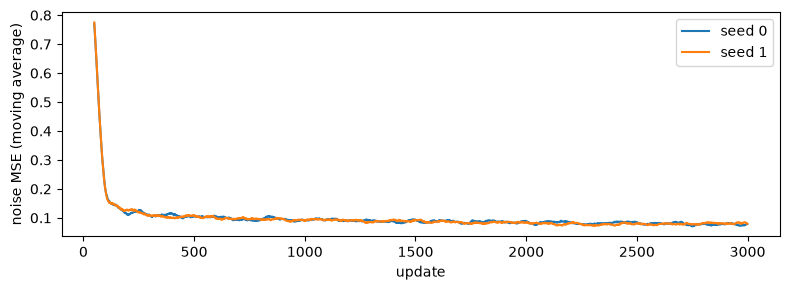

[{'final_step': 3000, 'elapsed_seconds': 185.46054058289155, 'stop_reason': 'max_steps'}, {'final_step': 3000, 'elapsed_seconds': 181.34165624994785, 'stop_reason': 'max_steps'}]


In [9]:
training = []
ema_models = {}
for seed in CFG["training"]["seeds"]:
    remaining = CFG["budget"]["compute_seconds"] - (time.monotonic() - COMPUTE_START)
    if remaining < 120:
        print("Budget guard: insufficient time for another training seed")
        break
    seed_all(seed)
    model = ConditionalDiTReference()
    schedule = DDPMScheduler(num_steps=1000, clip_denoised=False)
    config = TrainConfig(
        run_dir=str(RUN / f"seed_{seed}"),
        max_steps=CFG["training"]["steps"],
        max_seconds=min(CFG["training"]["max_seconds_per_seed"], remaining - 60),
        seed=seed,
        device=DEVICE,
        checkpoint_every=500,
        ema_decay=0.99,
        learning_rate=CFG["training"]["learning_rate"],
        scheduler_source="project_core",
        require_exact_resume=True,
    )
    summary = train_conditional(
        model,
        schedule,
        train_cache.latents,
        train_text_ids,
        features,
        masks,
        empty_id,
        drop_condition_reference,
        config,
        identity=DATA_ID,
        model_identity=MODEL_ID,
        batch_size=CFG["training"]["batch_size"],
        drop_probability=CFG["training"]["drop_probability"],
    )
    saved = torch.load(summary["checkpoint"], map_location="cpu", weights_only=True)
    ema = ConditionalDiTReference().to(DEVICE).eval().requires_grad_(False)
    ema.load_state_dict(saved["ema"])
    ema_models[seed] = ema
    training.append({k: v for k, v in summary.items() if k != "metrics"})
    del model, saved
RESULTS["training"] = training
fig, ax = plt.subplots(figsize=(8, 3))
for row in training:
    history = [
        json.loads(line)
        for line in (Path(row["checkpoint"]).parent / "metrics.jsonl").read_text().splitlines()
    ]
    loss = np.array([r["loss"] for r in history])
    width = min(50, len(loss))
    ax.plot(
        np.arange(width - 1, len(loss)),
        np.convolve(loss, np.ones(width) / width, mode="valid"),
        label=f"seed {row['config']['seed']}",
    )
ax.set(xlabel="update", ylabel="noise MSE (moving average)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "conditional_training.png")
plt.show()
print([{k: row[k] for k in ("final_step", "elapsed_seconds", "stop_reason")} for row in training])

## **六、先验证条件链路，再评价生成能力**

### **1. 四种不同强度的证据**

**一：输入可区分**，不同描述得到不同特征；仅证明编码器没有把输入全变成同一个值。**二：梯度可到达**，文本投影能更新；只证明工程连通。**三：固定 $z_t,t$ 的预测随条件改变**，证明网络在数值上使用条件。**四：真实生成在指定属性上优于打乱条件**，才接近本项目的目标。前三项均不能替代第四项。

随机时间的噪声 MSE 易被高噪声样本主导。比较正确、空和打乱条件时，必须使用 **相同图像、噪声和时间**，并按时间分桶报告。空文本与打乱文本不同：前者是训练中出现过的边际分支，后者是明确错误语义。打乱保持同一组条件的边际分布，每条必须语义不同，不能只交换两个同义模板。

单属性干预也固定初始噪声和采样配方：只变颜色，观察对应对象颜色；只变数量，观察个数；只反转一条关系，观察布局。有限结果可以失败；预测变化不自动等于属性方向正确。

In [10]:
rng = np.random.default_rng(20261104)
# 先固定 24 条验证请求，覆盖 1/2/3 对象，不查看测试图像。
val_indices = []
for count in (1, 2, 3):
    pool = [i for i, r in enumerate(val_records) if len(r["attributes"]["objects"]) == count]
    val_indices.extend(rng.choice(pool, 8, replace=False).tolist())
eval_records = [val_records[i] for i in val_indices]
shuffle = shuffled_indices(eval_records)
text_rows = torch.tensor([text_lookup[r["caption"]] for r in eval_records])
cond = features[text_rows].float().to(DEVICE)
cond_mask = masks[text_rows].to(DEVICE)
empty = features[empty_id : empty_id + 1].float().to(DEVICE)
empty_mask = masks[empty_id : empty_id + 1].to(DEVICE)
clean = val_cache.latents[val_indices].to(DEVICE)
noise = torch.randn(clean.shape, generator=torch.Generator().manual_seed(52)).to(DEVICE)
schedule = DDPMScheduler(num_steps=1000, clip_denoised=False).to(DEVICE)
probe_results = []
with torch.no_grad():
    for seed, model in ema_models.items():
        for t in (50, 250, 550, 850):
            times = torch.full((len(clean),), t, device=DEVICE, dtype=torch.long)
            noisy = schedule.add_noise(clean, noise, times)
            predictions = {
                "correct": model(noisy, times, cond, cond_mask),
                "empty": model(
                    noisy, times, empty.expand_as(cond), empty_mask.expand_as(cond_mask)
                ),
                "shuffled": model(noisy, times, cond[shuffle], cond_mask[shuffle]),
            }
            losses = {name: float((p - noise).square().mean()) for name, p in predictions.items()}
            probe_results.append(
                {
                    "seed": seed,
                    "t": t,
                    **losses,
                    "prediction_delta": float(
                        (predictions["correct"] - predictions["shuffled"]).square().mean()
                    ),
                }
            )
RESULTS["conditional_probe"] = probe_results
print(json.dumps(probe_results, indent=2))

[
  {
    "seed": 0,
    "t": 50,
    "correct": 0.29330477118492126,
    "empty": 0.3050268590450287,
    "shuffled": 0.300610214471817,
    "prediction_delta": 0.008275438100099564
  },
  {
    "seed": 0,
    "t": 250,
    "correct": 0.10972118377685547,
    "empty": 0.11697808653116226,
    "shuffled": 0.12824590504169464,
    "prediction_delta": 0.01732216402888298
  },
  {
    "seed": 0,
    "t": 550,
    "correct": 0.01758054457604885,
    "empty": 0.018384739756584167,
    "shuffled": 0.019224988296628,
    "prediction_delta": 0.0017117202514782548
  },
  {
    "seed": 0,
    "t": 850,
    "correct": 0.000893711403477937,
    "empty": 0.0009670937433838844,
    "shuffled": 0.0009526702924631536,
    "prediction_delta": 0.00014341605128720403
  },
  {
    "seed": 1,
    "t": 50,
    "correct": 0.2909543812274933,
    "empty": 0.29902324080467224,
    "shuffled": 0.29791703820228577,
    "prediction_delta": 0.007731006946414709
  },
  {
    "seed": 1,
    "t": 250,
    "correct": 

## **七、可信评测：比较请求，而不是比较隐藏渲染坐标**

### **1. 定义每个指标的分母**

第三周的重建诊断知道原图中心坐标，适合逐位置比较重建；文本生成并未收到精确像素中心，不能沿用隐藏中心来配对。新评分器只用请求里的颜色、形状、数量和关系。

| 指标 | 每图成功条件 | 分母 |
| --- | --- | --- |
| 数量 | 解析对象数与请求一致 | 全部图像 |
| 颜色 | 颜色多重集一致，且数量正确 | 全部图像 |
| 形状 | 形状多重集一致，且数量正确 | 全部图像 |
| 绑定 | `(颜色,形状)` 多重集一致 | 全部图像 |
| 关系 | 唯一绑定正确后，所有指定有向关系成立 | 含关系要求的图像；同时报告关系条数 |
| 综合 | 绑定及全部指定关系同时满足 | 全部图像 |
| 解析失败 | 不能得到 1–3 个可解析对象 | 全部图像 |

同图配对唯一，使“红圆”可以唯一指代。颜色和形状分别都对仍可能绑定错误，例如红方+蓝圆与请求红圆+蓝方。解析失败保持在总分母；颜色异常的可见物体可能被色板解析器漏掉，所以“解析有效”也不等于人类认为有效。

Wilson 区间适用于二元成功率，比小样本简单正态近似稳健。正确与打乱条件采用配对 bootstrap；它只表示该批请求/噪声下的样本不确定性，不能代替两个训练种子的重复。

### **2. 控制样本、真实生成与人工审核是三件事**

先用 100 张真实渲染图检查标准情况，再用 100 张退化图检查边界。退化包括空白（预期失败）和轻度模糊（属性理论保留），这些预期来自确定变换，不叫“人工标签”。然后输出至少 100 张生成或退化图的盲审包，分别记录颜色、形状、数量、关系与可识别性，人工字段初始留空。

本轮 Agent 可以抽查图像，不能代替你作为人工独立评审者的 100+100 张标注。正式 S3-04 在标注完成、规则一致性评估通过前保持进行中。生成域与标准几何图存在域差异，不能只在完美圆方上得分高就宣布解析器可靠。

独立人工审核请使用 `artifacts/runs/s3_conditional_v3/review/blind/human_review.jsonl`：匿名文件名、随机顺序，隐藏条件组和机器预测。代码保存的 `blind_review.jsonl` 是机器分析清单，不能让它的 parser 答案影响独立判断。Agent 运行 `scripts/evaluate_stage3_holdout.py --run-dir artifacts/runs/s3_conditional_v3 --prepare-review --notebook-reference` 可重建同身份包并保护已填标签；你只需给判断，Agent 录入和合并。

In [11]:
original_checks, degraded_checks = [], []
review_rows = []
review_dir = RUN / "review"
review_dir.mkdir(exist_ok=True)
for i in range(100):
    r = val_records[i]
    original = Image.open(ROOT / "data" / r["image_path"]).convert("RGB")
    original_checks.append(score_request(original, r))
    degraded = (
        Image.new("RGB", original.size, "white")
        if i % 2 == 0
        else original.filter(ImageFilter.GaussianBlur(0.6))
    )
    predicted = score_request(degraded, r)
    degraded_checks.append({"kind": "blank" if i % 2 == 0 else "blur_0.6", **predicted})
    for kind, image in (("original", original), ("degraded", degraded)):
        name = f"{kind}_{i:03d}.png"
        image.save(review_dir / name)
        review_rows.append(
            {
                "review_id": name,
                "image_path": name,
                "request": r["caption"],
                "parser": score_request(image, r),
                "human": None,
                "reviewer": None,
            }
        )
assert all(s["all"] == 1 for s in original_checks)
assert all(s["all"] == 0 for s in degraded_checks if s["kind"] == "blank")
RESULTS["parser_controls"] = {
    "originals": summarize(original_checks),
    "blank_correctly_failed": sum(s["all"] == 0 for s in degraded_checks if s["kind"] == "blank"),
    "blur_comprehensive_success": sum(s["all"] for s in degraded_checks if s["kind"] == "blur_0.6"),
    "human_review": "pending; controlled transformation labels are not human annotations",
}
print(RESULTS["parser_controls"])

{'originals': {'count': 1.0, 'color': 1.0, 'shape': 1.0, 'binding': 1.0, 'all': 1.0, 'parse_failure': 0.0, 'images': 100, 'relation_images': 58, 'relation': 1.0, 'relation_denominator': 138, 'all_wilson95': [0.9630065017930143, 1.0]}, 'blank_correctly_failed': 50, 'blur_comprehensive_success': 50, 'human_review': 'pending; controlled transformation labels are not human annotations'}


## **八、完整采样对照、CFG 选型与成本**

### **1. DDIM 跨步更新为什么能节省求值**

DDPM 相邻更新必须逐级运行。本轮额外实现 DDIM 的确定性版本（$\eta=0$），才能诚实比较 10/20/40 次更新。给定当前索引 $t$ 与下一个较小索引 $s$：

$$\widehat z_0=\frac{z_t-\sqrt{1-\bar\alpha_t}\,\widehat\epsilon}{\sqrt{\bar\alpha_t}}$$

$$z_s=\sqrt{\bar\alpha_s}\,\widehat z_0+\sqrt{1-\bar\alpha_s}\,\widehat\epsilon$$

最终干净端点使用 $\bar\alpha_{-1}=1$，而代码索引 0 仍是加过一次噪声。$\eta=0$ 的确定性指给定模型、文本与初始噪声后的轨迹；初始噪声仍随机。子序列、日程和更新规则一起改变，不把 DDPM 循环直接跳步。[DDIM](https://arxiv.org/abs/2010.02502v4) 第 4.1 节式 (12) 与附录 C.1 是对应依据。

**计算账本**：40 次更新、$s=1$，每张图 40 个分支等价 NFE；$s=3$，是 80，而不是 40。将两个分支合成一个 2b batch 可减少 Python 调用与开销，但没有免费消除计算。报告更新数、模型调用数、每图等价 NFE、分支样本总数、延迟与吞吐。

测量前预热，并同步 MPS/CUDA。纯去噪时间与包含在线文本编码、VAE 解码的端到端时间分开记录。MPS 没有与 CUDA 同口径的重置峰值显存 API，本轮写“不可用”，不拿当前分配量冒充峰值。

In [12]:
vae = FrozenVAE.load(ROOT, ROOT / "configs/models/sdxl_vae.json", DEVICE)
initial = torch.randn(
    (len(eval_records), 4, 16, 16), generator=torch.Generator().manual_seed(41)
).to(DEVICE)
# 固定验证集，只用 seed 0 选择 CFG，seed 1 不参与选型。
selection = []
selection_model = ema_models[0]
_ = sample_conditional(
    selection_model,
    schedule,
    initial[:2],
    cond[:2],
    cond_mask[:2],
    empty,
    empty_mask,
    cfg_reference,
    method="ddim",
    steps=2,
    scale=1,
)
for scale in CFG["selection"]["cfg_candidates"]:
    generated = sample_conditional(
        selection_model,
        schedule,
        initial,
        cond,
        cond_mask,
        empty,
        empty_mask,
        cfg_reference,
        scale=scale,
        method="ddim",
        steps=40,
    )
    assert generated["completed"]
    images = [to_image(x) for x in vae.decode(generated["images"])]
    scores = [score_request(image, r) for image, r in zip(images, eval_records, strict=True)]
    selection.append({"scale": scale, "metrics": summarize(scores)})
# 预先约定综合成功率最高，平局取较小 CFG；不在看测试后改目标。
selected_scale = max(selection, key=lambda row: (row["metrics"]["all"], -row["scale"]))["scale"]
freeze = {
    "config_sha256": RESULTS["config_sha256"],
    "selection": selection,
    "selected_scale": selected_scale,
    "validation_sample_ids": [r["sample_id"] for r in eval_records],
    "test_opened": False,
}
(RUN / "selection_frozen.json").write_text(json.dumps(freeze, indent=2) + "\n")
RESULTS["selection"] = freeze
print(json.dumps(selection, indent=2), "selected", selected_scale)

[
  {
    "scale": 1.0,
    "metrics": {
      "count": 0.3333333333333333,
      "color": 0.25,
      "shape": 0.08333333333333333,
      "binding": 0.041666666666666664,
      "all": 0.041666666666666664,
      "parse_failure": 0.375,
      "images": 24,
      "relation_images": 16,
      "relation": 0.0,
      "relation_denominator": 49,
      "all_wilson95": [
        0.0073934561655057685,
        0.20241806478655938
      ]
    }
  },
  {
    "scale": 3.0,
    "metrics": {
      "count": 0.3333333333333333,
      "color": 0.2916666666666667,
      "shape": 0.08333333333333333,
      "binding": 0.08333333333333333,
      "all": 0.08333333333333333,
      "parse_failure": 0.5,
      "images": 24,
      "relation_images": 16,
      "relation": 0.0,
      "relation_denominator": 49,
      "all_wilson95": [
        0.023158815297043306,
        0.25848802193210685
      ]
    }
  },
  {
    "scale": 5.0,
    "metrics": {
      "count": 0.20833333333333334,
      "color": 0.08333333333

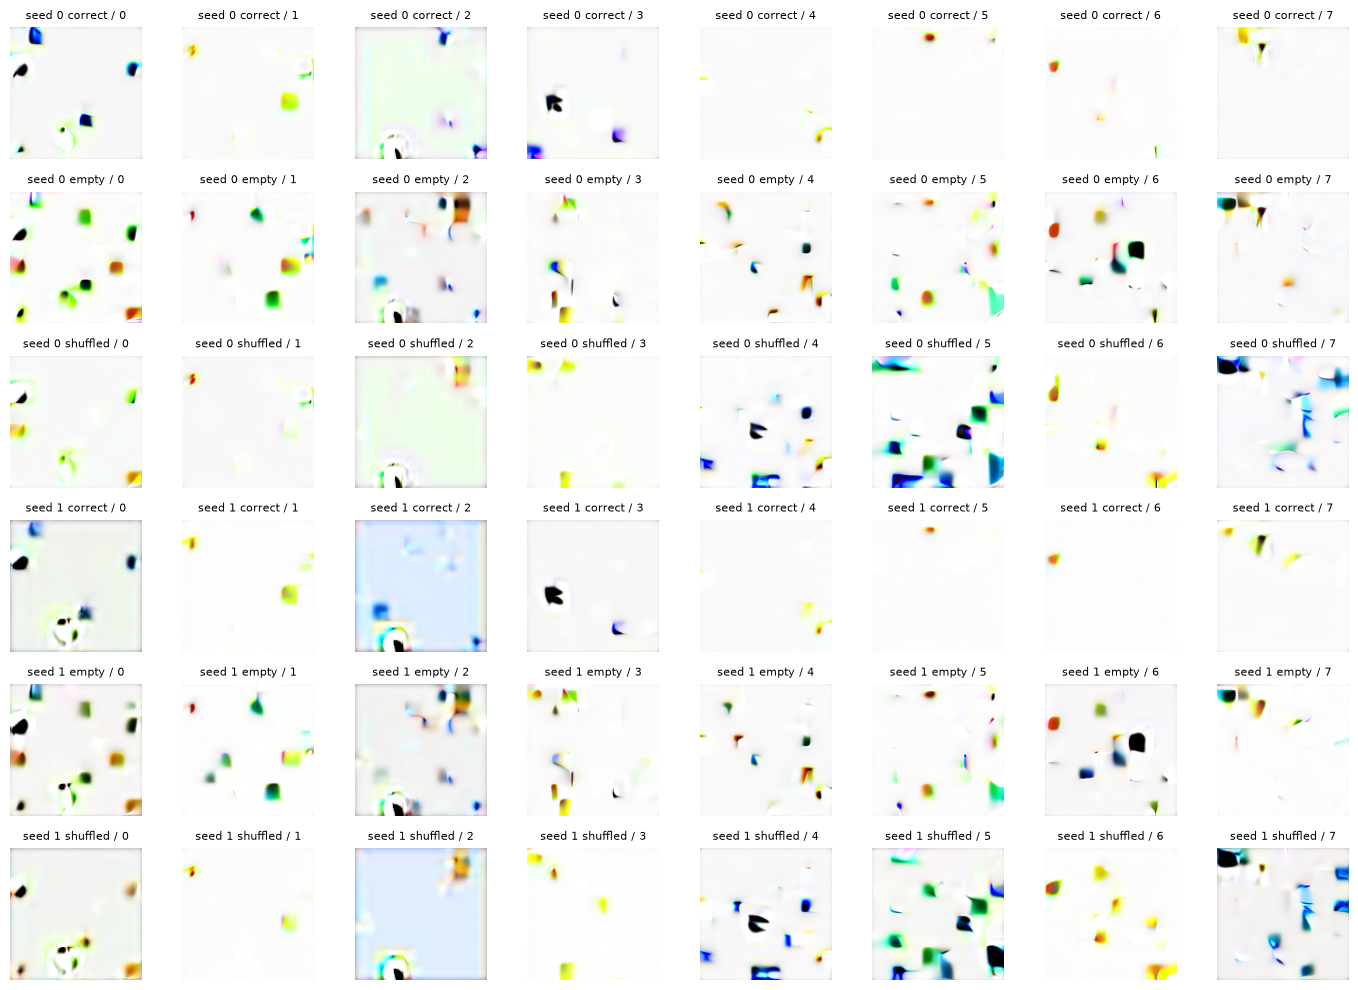

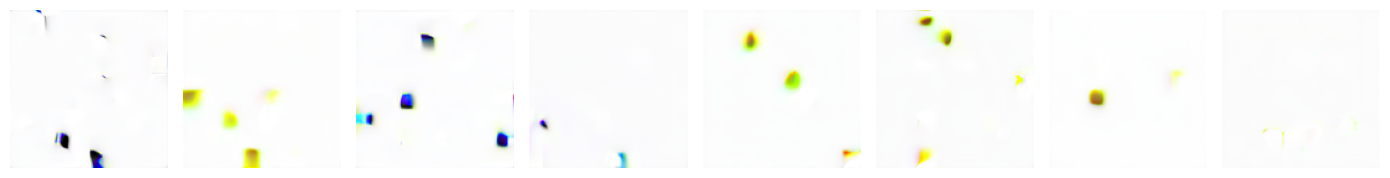

[
  {
    "seed": 0,
    "paired_gain": {
      "difference": 0.08333333333333333,
      "bootstrap95": [
        0.0,
        0.20833333333333334
      ],
      "pairs": 24,
      "limitation": "sample-level only; report each training seed separately"
    }
  },
  {
    "seed": 1,
    "paired_gain": {
      "difference": 0.041666666666666664,
      "bootstrap95": [
        0.0,
        0.125
      ],
      "pairs": 24,
      "limitation": "sample-level only; report each training seed separately"
    }
  }
]


In [13]:
control_rows = []
control_images = {}
for seed, model in ema_models.items():
    outcomes = {}
    for name in ("correct", "empty", "shuffled"):
        c_now, m_now = (
            (cond, cond_mask)
            if name == "correct"
            else (
                (empty.expand_as(cond), empty_mask.expand_as(cond_mask))
                if name == "empty"
                else (cond[shuffle], cond_mask[shuffle])
            )
        )
        generated = sample_conditional(
            model,
            schedule,
            initial,
            c_now,
            m_now,
            empty,
            empty_mask,
            cfg_reference,
            scale=selected_scale,
            method="ddim",
            steps=40,
        )
        assert generated["completed"]
        images = [to_image(x) for x in vae.decode(generated["images"])]
        scores = [score_request(image, r) for image, r in zip(images, eval_records, strict=True)]
        outcomes[name] = [s["all"] for s in scores]
        control_images[(seed, name)] = images
        control_rows.append(
            {
                "seed": seed,
                "condition": name,
                "metrics": summarize(scores),
                "sampling": {k: v for k, v in generated.items() if k != "images"},
                "sample_ids": [r["sample_id"] for r in eval_records],
            }
        )
        for i, (image, r, score) in enumerate(zip(images, eval_records, scores, strict=True)):
            filename = f"generated_{seed}_{name}_{i:03d}.png"
            image.save(review_dir / filename)
            review_rows.append(
                {
                    "review_id": filename,
                    "image_path": filename,
                    "request": r["caption"],
                    "parser": score,
                    "human": None,
                    "reviewer": None,
                }
            )
    control_rows.append(
        {
            "seed": seed,
            "paired_gain": paired_difference(outcomes["correct"], outcomes["shuffled"], seed),
        }
    )
RESULTS["controls"] = control_rows
fig, axes = plt.subplots(6, 8, figsize=(14, 10))
for row, key in enumerate(control_images):
    for i in range(8):
        axes[row, i].imshow(control_images[key][i])
        axes[row, i].axis("off")
        axes[row, i].set_title(f"seed {key[0]} {key[1]} / {i}", fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "paired_controls.png", dpi=140)
plt.show()
# 8 张完整 1000 步 DDPM，与 DDIM 结果分开展示；不是跳步后的伪 DDPM。
full = sample_conditional(
    ema_models[0],
    schedule,
    initial[:8],
    cond[:8],
    cond_mask[:8],
    empty,
    empty_mask,
    cfg_reference,
    scale=selected_scale,
    method="ddpm",
    steps=1000,
)
RESULTS["full_ddpm"] = {k: v for k, v in full.items() if k != "images"}
assert full["completed"]
full_images = [to_image(x) for x in vae.decode(full["images"])]
fig, axes = plt.subplots(1, 8, figsize=(14, 2))
for ax, image in zip(axes, full_images, strict=True):
    ax.imshow(image)
    ax.axis("off")
fig.tight_layout()
fig.savefig(FIG / "full_ddpm.png", dpi=140)
plt.show()
print(json.dumps([r for r in control_rows if "paired_gain" in r], indent=2))

这里补齐 **所有 24 条验证请求** 的图组。前图是编号 0–7（一个对象）；下图依次为 8–15（两个对象）和 16–23（三个对象），顺序在采样前固定，没有按结果挑选。行分别是两个训练种子的正确、空与打乱条件。全部描述见 [固定验证请求](../../reports/stage3/validation_prompts.json)，原图和盲审记录在本地 review 目录。

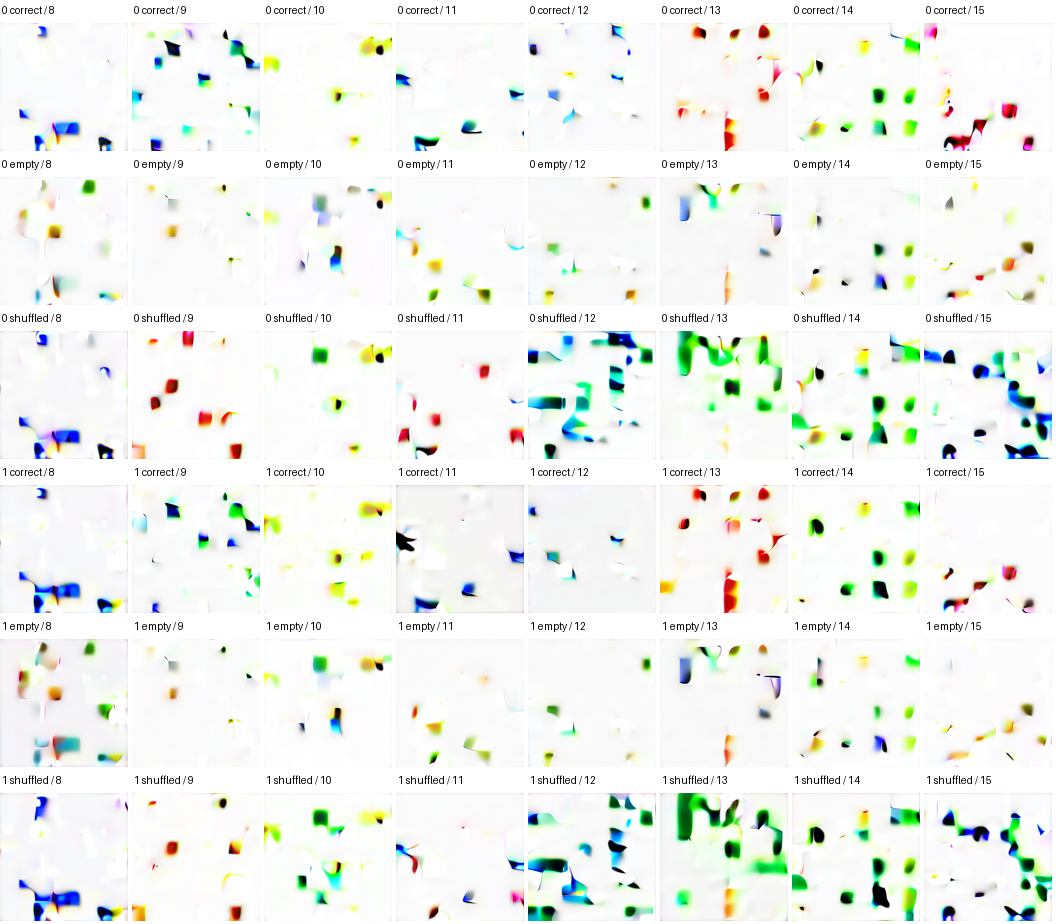

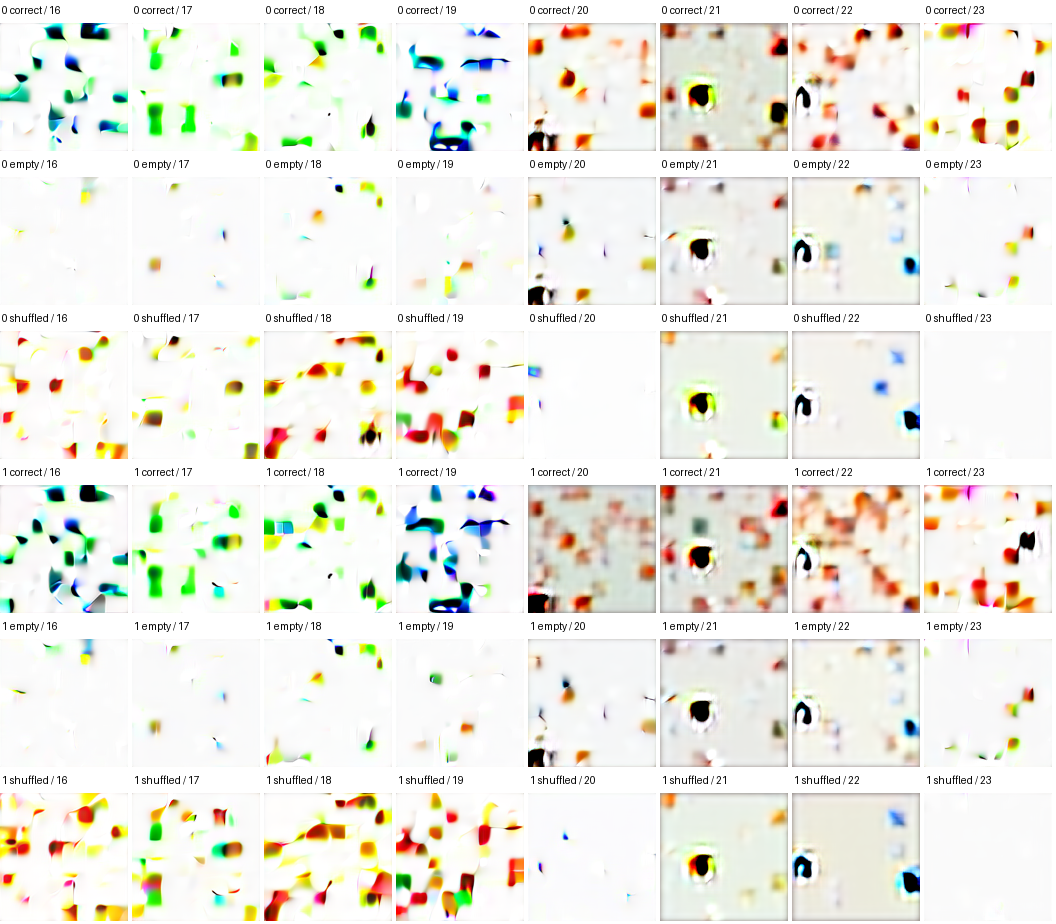

附件是 s3_conditional_v3 的交付快照；改变配置或重跑后，以新 review 目录为准，Agent 同步更新附件。

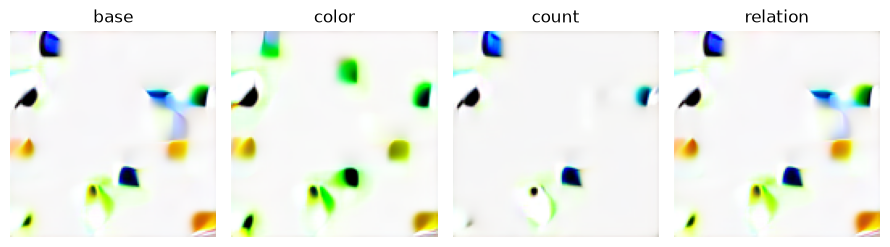

[
  {
    "attribute": "base",
    "prompt": "On a white background: a blue triangle, a yellow square. Positions: the blue triangle is above the yellow square.",
    "score": {
      "count": 0,
      "color": 0,
      "shape": 0,
      "binding": 0,
      "relation_hits": 0,
      "relation_total": 1,
      "has_relation": 1,
      "relation_all": 0,
      "all": 0,
      "parse_failure": 1
    }
  },
  {
    "attribute": "color",
    "prompt": "On a white background: a green triangle, a yellow square. Positions: the green triangle is above the yellow square.",
    "score": {
      "count": 0,
      "color": 0,
      "shape": 0,
      "binding": 0,
      "relation_hits": 0,
      "relation_total": 1,
      "has_relation": 1,
      "relation_all": 0,
      "all": 0,
      "parse_failure": 1
    }
  },
  {
    "attribute": "count",
    "prompt": "On a white background: a blue triangle.",
    "score": {
      "count": 1,
      "color": 1,
      "shape": 0,
      "binding": 0,
      "rela

In [14]:
# 基于两个对象的同一请求，分别只改变颜色、数量和一条关系。
base = copy.deepcopy(
    next(
        r
        for r in eval_records
        if len(r["attributes"]["objects"]) == 2 and r["attributes"]["relations"]
    )
)
variants = [("base", base)]
color_variant = copy.deepcopy(base)
used = {(o["color"], o["shape"]) for o in base["attributes"]["objects"][1:]}
color_variant["attributes"]["objects"][0]["color"] = next(
    c
    for c in ("red", "blue", "green", "yellow")
    if (c, base["attributes"]["objects"][0]["shape"]) not in HELD
    and c != base["attributes"]["objects"][0]["color"]
    and (c, base["attributes"]["objects"][0]["shape"]) not in used
)
variants.append(("color", color_variant))
count_variant = copy.deepcopy(base)
count_variant["attributes"]["objects"] = count_variant["attributes"]["objects"][:1]
count_variant["attributes"]["relations"] = []
count_variant["attributes"]["count"] = 1
variants.append(("count", count_variant))
relation_variant = copy.deepcopy(base)
r = relation_variant["attributes"]["relations"][0]
r["subject"], r["object"] = r["object"], r["subject"]
variants.append(("relation", relation_variant))
for _, r in variants:
    r["caption"] = caption(r["attributes"]["objects"], r["attributes"]["relations"])
text_encoder.model.to(DEVICE)
text_encoder.device = DEVICE
vfeatures, vmask, _ = text_encoder.encode([r["caption"] for _, r in variants])
text_encoder.model.to("cpu")
vresult = sample_conditional(
    ema_models[0],
    schedule,
    initial[:1].expand(4, -1, -1, -1),
    vfeatures.to(DEVICE),
    vmask.to(DEVICE),
    empty,
    empty_mask,
    cfg_reference,
    scale=selected_scale,
    method="ddim",
    steps=40,
)
assert vresult["completed"]
vimages = [to_image(x) for x in vae.decode(vresult["images"])]
RESULTS["interventions"] = [
    {"attribute": name, "prompt": r["caption"], "score": score_request(image, r)}
    for (name, r), image in zip(variants, vimages, strict=True)
]
fig, axes = plt.subplots(1, 4, figsize=(9, 3))
for ax, (name, _), image in zip(axes, variants, vimages, strict=True):
    ax.imshow(image)
    ax.set_title(name)
    ax.axis("off")
fig.tight_layout()
fig.savefig(FIG / "interventions.png", dpi=140)
plt.show()
print(json.dumps(RESULTS["interventions"], indent=2))

In [15]:
efficiency = []
for steps in CFG["efficiency"]["update_budgets"]:
    for scale in (1.0, 3.0):
        _ = sample_conditional(
            ema_models[0],
            schedule,
            initial[:8],
            cond[:8],
            cond_mask[:8],
            empty,
            empty_mask,
            cfg_reference,
            method="ddim",
            steps=2,
            scale=scale,
        )
        repeats = []
        for _ in range(3):
            measured = sample_conditional(
                ema_models[0],
                schedule,
                initial[:8],
                cond[:8],
                cond_mask[:8],
                empty,
                empty_mask,
                cfg_reference,
                method="ddim",
                steps=steps,
                scale=scale,
            )
            repeats.append({k: v for k, v in measured.items() if k != "images"})
        efficiency.append(
            {
                "updates": steps,
                "scale": scale,
                "median_seconds": float(np.median([r["elapsed_seconds"] for r in repeats])),
                "repeats": repeats,
            }
        )
# 在线文本编码 + 去噪 + VAE 解码；模型已加载，冷启动/下载不在此计时中。
text_encoder.model.to(DEVICE)
synchronize(torch.device(DEVICE))
start = time.monotonic()
online_c, online_m, _ = text_encoder.encode([r["caption"] for r in eval_records[:8]])
online = sample_conditional(
    ema_models[0],
    schedule,
    initial[:8],
    online_c.to(DEVICE),
    online_m.to(DEVICE),
    empty,
    empty_mask,
    cfg_reference,
    method="ddim",
    steps=40,
    scale=selected_scale,
)
online_pixels = vae.decode(online["images"])
synchronize(torch.device(DEVICE))
e2e = time.monotonic() - start
text_encoder.model.to("cpu")
RESULTS["efficiency"] = {
    "measurements": efficiency,
    "online_text_denoise_decode_seconds": e2e,
    "scope": "warm loaded models, batch=8, FP32, no file I/O; cached empty text",
    "online_vs_FP16_cache": "online uses FP32 features; not a bitwise cache equivalence claim",
}
print([{k: r[k] for k in ("updates", "scale", "median_seconds")} for r in efficiency])
print("loaded-model end-to-end seconds", e2e)

[{'updates': 10, 'scale': 1.0, 'median_seconds': 0.06341245817020535}, {'updates': 10, 'scale': 3.0, 'median_seconds': 0.088749208021909}, {'updates': 20, 'scale': 1.0, 'median_seconds': 0.12878195801749825}, {'updates': 20, 'scale': 3.0, 'median_seconds': 0.24737549992278218}, {'updates': 40, 'scale': 1.0, 'median_seconds': 0.29951824992895126}, {'updates': 40, 'scale': 3.0, 'median_seconds': 0.47824720898643136}]
loaded-model end-to-end seconds 1.5137588751967996


### **2. 最近邻、测试封存和结论的边界**

最接近训练样本不一定是记忆，尤其在低维几何数据中许多场景天然相似；但完全重复仍值得检查。这里保存完整 DDPM 样本与最近训练潜变量的 L2 距离及对应原图，作为诊断，不称为语义相似度或正式隐私测试。

最终测试必须先冻结选型，再满足条件收益、个人核心和评测器可靠性门槛。收益不成立时继续修链路，**不打开测试来寻找好看的组合**。分布内、组合外、模板外的配置和后续命令在任务包中保留；本轮若未过门槛，它们的结果明确为待运行。

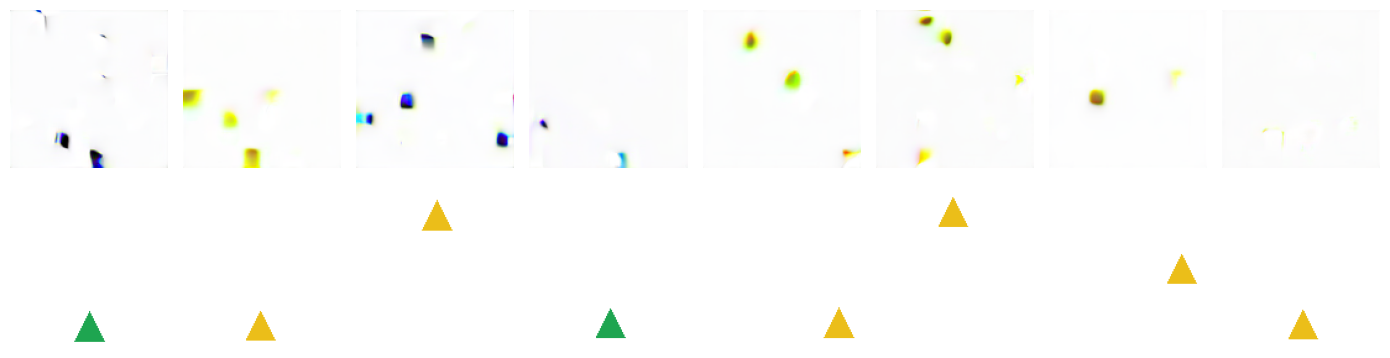

{'opened': False, 'splits': ['test_id', 'test_combo', 'test_template'], 'positive_gain_seeds': [0, 1], 'prerequisites': {'positive_gain_both_seeds': True, 'human_parser_acceptance': False, 'personal_DiT_CFG_acceptance': False}, 'reason': 'Formal gate is not met; keep tests sealed. No test results fabricated.'}


In [16]:
nearest_distance = torch.cdist(full["images"].flatten(1), train_cache.latents.flatten(1))
nearest_values, nearest_ids = nearest_distance.min(-1)
RESULTS["nearest_neighbors"] = [
    {"sample": i, "train_sample_id": train_records[j]["sample_id"], "latent_l2": float(d)}
    for i, (j, d) in enumerate(zip(nearest_ids.tolist(), nearest_values, strict=True))
]
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, j in enumerate(nearest_ids.tolist()):
    axes[0, i].imshow(full_images[i])
    axes[1, i].imshow(Image.open(ROOT / "data" / train_records[j]["image_path"]))
    axes[0, i].axis("off")
    axes[1, i].axis("off")
fig.tight_layout()
fig.savefig(FIG / "nearest_neighbors.png", dpi=140)
plt.show()
positive_seeds = [
    r["seed"] for r in control_rows if "paired_gain" in r and r["paired_gain"]["difference"] > 0
]
RESULTS["holdout"] = {
    "opened": False,
    "splits": CFG["holdout"]["splits"],
    "positive_gain_seeds": positive_seeds,
    "prerequisites": {
        "positive_gain_both_seeds": len(positive_seeds) == 2,
        "human_parser_acceptance": False,
        "personal_DiT_CFG_acceptance": False,
    },
    "reason": "Formal gate is not met; keep tests sealed. No test results fabricated.",
}
(review_dir / "blind_review.jsonl").write_text(
    "\n".join(json.dumps(r, ensure_ascii=False) for r in review_rows) + "\n"
)
print(RESULTS["holdout"])

## **九、Flow 预研：从预测噪声转到预测速度**

### **1. 点对路径、条件速度与边际速度**

现在只在二维理解下一阶段问题，不训练图像 Flow，也不补写个人 L05。取噪声 $\epsilon\sim\mathcal N(0,I)$、数据 $z\sim p_{\mathrm{data}}$，独立配对，时间方向明确为 **噪声 0 → 数据 1**：

$$z_t=(1-t)\epsilon+tz,\qquad u_t=\frac{d z_t}{dt}=z-\epsilon$$

$$L_{\mathrm{CFM}}=\mathbb E_{z,\epsilon,t}\left[\lVert v_\theta(z_t,t)-(z-\epsilon)\rVert_2^2\right]$$

给定同一 $z_t$ 可能来自许多端点对，网络没看见真实端点。平方回归的最优预测是条件期望。令 $U=z-\epsilon$、$X=z_t$，展开：

$$\mathbb E[\lVert v(X,t)-U\rVert^2\mid X]=\lVert v(X,t)-\mathbb E[U\mid X]\rVert^2+\mathbb E[\lVert U-\mathbb E[U\mid X]\rVert^2\mid X]$$

交叉项为零，因为 $\mathbb E[U-\mathbb E(U\mid X)\mid X]=0$。所以监督随机点对速度能学到边际场 $v^*(x,t)=\mathbb E[z-\epsilon\mid z_t=x]$。这不是让每个样本记住自己的直线，也不是全局最优传输配对；本轮是 **独立端点耦合** 的线性条件路径。对应 [Flow Matching](https://arxiv.org/abs/2210.02747v2) 的条件回归思想，端点取零残余噪声的教学特例；不要把独立耦合称作求解了全局 OT。

采样解常微分方程 ODE：$d z/dt=v_\theta(z,t)$，Euler 正向更新为 $z_{k+1}=z_k+\Delta t\,v_\theta(z_k,t_k)$。直线监督不代表学到的边际场沿自身轨迹恒定，减少成一步会产生积分误差。

### **2. 可以手算的二维基准**

设数据为二维高斯 $z\sim\mathcal N(m,\sigma^2I)$、噪声为标准高斯，且相互独立。线性组合仍为高斯：

$$\mu_t=tm,\quad a_t=(1-t)^2+t^2\sigma^2,\quad \operatorname{Cov}(U,z_t)=\big[t\sigma^2-(1-t)\big]I$$

利用联合高斯条件期望：

$$v^*(x,t)=m+\frac{t\sigma^2-(1-t)}{a_t}(x-tm)$$

> **数值例**：$m=(2,-1)$、$\sigma=0.5$、$t=0.5$，$a_t=0.3125$，协方差系数 $0.125-0.5=-0.375$，比例为 $-1.2$。在 $x=(1.5,0)$，$x-tm=(0.5,0.5)$，速度为 $(1.4,-1.6)$。这不是简单的 $m-x$。

连续精确流把初始 $x_0$ 变成 $x_t=tm+\sqrt{a_t}x_0$，终点为 $m+\sigma x_0$。我们用这个解析解检查 Euler 误差随 10/20/40 步缩小，再用小 MLP 学随机点对目标。端点均值/方差接近仍不足以证明任意分布质量，这里只是已知高斯的低维验证。

In [17]:
def flow_path_reference(data, noise, time):
    """独立端点线性条件路径，time 为 [b,1]，方向 noise -> data。"""
    return (1 - time) * noise + time * data, data - noise


def euler_reference(field, initial, steps):
    """用正时间增量积分外部速度场；不是 DDPM step。"""
    state = initial.clone()
    trajectory = [state.clone()]
    for k in range(steps):
        time_value = torch.full((len(state), 1), k / steps, dtype=state.dtype)
        state = state + field(state, time_value) / steps
        trajectory.append(state.clone())
    return state, torch.stack(trajectory)


def gaussian_velocity_reference(x, t):
    mean = x.new_tensor([2.0, -1.0])
    variance = (1 - t).square() + 0.25 * t.square()
    coefficient = (0.25 * t - (1 - t)) / variance
    return mean + coefficient * (x - t * mean)

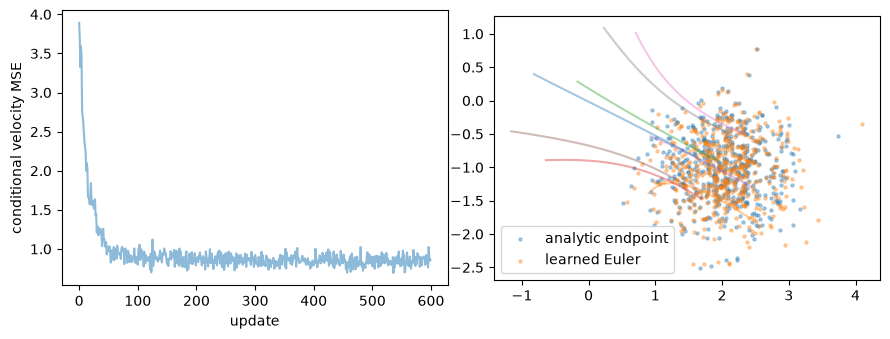

{'source': 'notebook_reference', 'steps': 600, 'device': 'cpu', 'elapsed_seconds': 0.902142042061314, 'analytic_euler_errors': [{'steps': 10, 'endpoint_rmse': 0.06827691197395325}, {'steps': 20, 'endpoint_rmse': 0.035266753286123276}, {'steps': 40, 'endpoint_rmse': 0.017942044883966446}], 'first50_mean_loss': 1.769539576768875, 'last50_mean_loss': 0.8565105724334717, 'endpoint_mean': [2.0303430557250977, -1.0444836616516113], 'endpoint_variance': [0.2410813868045807, 0.24351662397384644], 'scope': '2D Gaussian, independent endpoint coupling; not image flow or global OT'}


In [18]:
seed_all(7)
start_points = torch.randn(512, 2)
exact = torch.tensor([2.0, -1.0]) + 0.5 * start_points
errors = []
for steps in (10, 20, 40):
    endpoint, trajectory = euler_reference(gaussian_velocity_reference, start_points, steps)
    errors.append(
        {"steps": steps, "endpoint_rmse": float((endpoint - exact).square().mean().sqrt())}
    )
assert errors[2]["endpoint_rmse"] < errors[1]["endpoint_rmse"] < errors[0]["endpoint_rmse"]
# 常速度场检查方向和终点，不依赖网络拟合。
constant, _ = euler_reference(lambda x, t: torch.ones_like(x) * 2, torch.zeros(3, 2), 10)
assert torch.allclose(constant, torch.full((3, 2), 2.0))
assert torch.allclose(
    gaussian_velocity_reference(torch.tensor([[1.5, 0.0]]), torch.tensor([[0.5]])),
    torch.tensor([[1.4, -1.6]]),
)
flow_net = nn.Sequential(
    nn.Linear(3, 64), nn.SiLU(), nn.Linear(64, 64), nn.SiLU(), nn.Linear(64, 2)
)
flow_opt = torch.optim.Adam(flow_net.parameters(), lr=0.002)
flow_losses = []
flow_start = time.monotonic()
for _step in range(CFG["flow_toy"]["steps"]):
    data = torch.randn(256, 2) * 0.5 + torch.tensor([2.0, -1.0])
    noise = torch.randn_like(data)
    time_value = torch.rand(256, 1)
    state, velocity = flow_path_reference(data, noise, time_value)
    loss = (flow_net(torch.cat([state, time_value], -1)) - velocity).square().mean()
    flow_opt.zero_grad()
    loss.backward()
    flow_opt.step()
    flow_losses.append(float(loss.detach()))
with torch.no_grad():
    learned, trajectory = euler_reference(
        lambda x, t: flow_net(torch.cat([x, t], -1)), start_points, 40
    )
RESULTS["flow_toy"] = {
    "source": "notebook_reference",
    "steps": len(flow_losses),
    "device": "cpu",
    "elapsed_seconds": time.monotonic() - flow_start,
    "analytic_euler_errors": errors,
    "first50_mean_loss": float(np.mean(flow_losses[:50])),
    "last50_mean_loss": float(np.mean(flow_losses[-50:])),
    "endpoint_mean": learned.mean(0).tolist(),
    "endpoint_variance": learned.var(0, unbiased=False).tolist(),
    "scope": "2D Gaussian, independent endpoint coupling; not image flow or global OT",
}
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
axes[0].plot(flow_losses, alpha=0.5)
axes[0].set(xlabel="update", ylabel="conditional velocity MSE")
axes[1].scatter(exact[:, 0], exact[:, 1], s=5, alpha=0.35, label="analytic endpoint")
axes[1].scatter(learned[:, 0], learned[:, 1], s=5, alpha=0.35, label="learned Euler")
for i in range(8):
    axes[1].plot(trajectory[:, i, 0], trajectory[:, i, 1], alpha=0.4)
axes[1].legend()
axes[1].set_aspect("equal")
fig.tight_layout()
fig.savefig(FIG / "flow_toy.png", dpi=140)
plt.show()
print(RESULTS["flow_toy"])

## **十、研究设计、现代适配与前沿阅读**

### **1. 下一阶段只比较明确的两套配方**

正式研究问题：相同条件 DiT、图像与文本缓存、有效 batch、优化器和 EMA 下，噪声预测扩散+DDIM 与线性 Flow Matching+Euler，在条件遵循、组合泛化和计算成本上各有什么表现？

| 训练配方 | 训练种子 | 采样预算 | 不能混淆 |
| --- | --- | --- | --- |
| epsilon DDPM | 0、1 | 每图等价 NFE=10/20/40 | 与 DDIM 更新次数及 CFG 分支数分别登记 |
| linear CFM | 0、1 | 每图等价 NFE=10/20/40 | 速度输出不能接噪声采样器 |

先跑约 200 步估时，四组采用共同可负担更新上限，目标最多 8000。既报告同更新步数，也保存中间权重比较累计 GPU 时间。不能比较原始两种 loss 数值断定哪种生成好；路径、时间和求解器都改变，本质上比较的是两套配方。

CFG 若 $s>1$，10/20/40 等价 NFE 对应 5/10/20 次双分支更新；另外附 10/20/40 更新的表，避免偷换预算。若选到 $s=1$ 则一一对应。配置见 [S4 预登记](../../configs/experiments/s4_preregistered.yaml)。本轮没有云 GPU 单价测量，100–300 元是总预算上限，不是报价或已花费用。

### **2. Sana LoRA 可行性：预研不能写成微调通过**

B 线仍选 Sana 600M 512px 作为候选，组件与本项目 SDXL VAE/CLIP 不兼容复用。[模型卡](https://huggingface.co/Efficient-Large-Model/Sana_600M_512px_diffusers) 和 [Diffusers 官方 LoRA 示例](https://github.com/huggingface/diffusers/blob/main/examples/dreambooth/README_sana.md) 是准备入口；固定版本及显存必须在实际运行前核验。600M 只表示生成主干规模，文本网络、Autoencoder、激活和优化器另占内存。

先记录模型与素材许可、访问约束、组件大小，再做本地/单卡加载推理与 **50 步真实 LoRA 更新**，打印可训练 rank-8 参数、记录显存/耗时、保存后新进程加载。通过后才准备 200–400 张按主体/变体分组的 OpenMoji 子集，逐图描述，约 80/10/10 划分。不能用一句“OpenMoji style”替代所有主体描述。

本轮只形成可执行任务与失败分支，不下载完整模型、不调用付费 GPU、不采集 OpenMoji，不把这段说明当作模型可行性通过。材料许可、代码许可、权重许可分别登记；风格盲评和几何图规则评测分开。细节见 [B 线预研](../../reports/research/s3_sana_feasibility.md)。

### **3. 三张研究卡：问题驱动，避免提前扩张**

**REPA** 研究生成训练中间表示的学习效率，用冻结视觉教师的干净图像特征监督去噪网络中间层的投影。论文在其大规模设置给出收敛和质量证据；本项目未实测。图标与通用自然图像教师存在域差异，先测试教师是否区分颜色、数量与空间，再考虑实现。它改训练监督，不是另一个采样器。[论文](https://arxiv.org/abs/2410.06940v4)。

**RAE** 使用预训练表示编码器配训练解码器形成 Representation Autoencoder，并让生成主干适应更高维潜空间。它不是简单把 DINO 特征塞进原 4 通道 VAE 接口：尺度、噪声与计算量都要重建基线。本项目当前重建已过门槛、生成仍差，应先修条件与主干训练，不能凭热点断定换表示必胜。[论文](https://arxiv.org/abs/2510.11690v1)。

**MeanFlow** 对时间区间平均速度建模，联系瞬时速度并构造训练约束，目标包括一步生成。普通 Flow 的 Euler 直接减成一步只是粗积分，不等于训练了平均速度模型。先把二维速度与积分误差理解清楚，后续只有推理成本成为主要瓶颈才探索。[论文](https://arxiv.org/abs/2505.13447v1)。

以上按 2026-11-04 可核验的一手资料整理，是与本项目瓶颈有关的阅读线索，不称为整个领域的最新最终答案。完整一页卡的动机、机制、论文证据、失效条件和项目联系见 [研究卡](../../reports/research/s3_research_cards.md)。

## **十一、带答案的自测与个人接手**

### **1. 合上代码后回答**

1. **图像 token 和文本 token 数不同，为什么仍能注意力？** Q/K 投影到相同头宽度即可点积，分数矩阵是 $n_x\times n_y$，不要求两个 token 数相等。
2. **为什么空条件不能是全 False mask？** softmax 没有有效文本位置；训练的空文本应该保留其 BOS/EOS，采样使用同一表示。
3. **CFG 的 scale=1 为什么可以少一次分支求值？** $\epsilon_u+1(\epsilon_c-\epsilon_u)=\epsilon_c$；直接运行条件预测即可，不意味着两个模型权重不同。
4. **loss 随正确条件下降，能宣布条件有效吗？** 仍可能依赖时间或布局先验；还需要固定输入预测变化、真实生成属性收益、两个训练种子及可信评测。
5. **为什么不能沿原图像素中心匹配生成物体？** 描述没给精确中心，这会惩罚未请求的位置变化并隐含使用额外监督。按颜色形状唯一指代和指定关系评分。
6. **两个种子的 24 张样本能证明通用文本生成吗？** 不能，受控词汇、样本量、训练预算和解析器域限制都存在；组合外与模板外需独立测试。
7. **Flow 的 $z-\epsilon$ 与网络实际最优输出相同吗？** 前者是给定端点对的监督，后者是给定当前位置和时间的条件期望；不同端点路径相交时不能恢复每对端点。
8. **40 次双分支更新有多少 NFE？** 每图 80 个分支等价 NFE；合批可只有 40 次 Python 调用，图像数为 b 时总分支样本数为 $80b$。
9. **数据潜变量总体均值方差接近标准正态，能证明 VAE 条件 KL 小吗？** 不能。条件后验 KL 与聚合分布矩不同，S1 的反例仍适用。
10. **个人作业下一步是什么？** 先完成 L03 并通过独立 patch/门控测试，再完成 L04 条件注入和 CFG。教学对象明确传入，不能写一个自动 fallback 让测试变绿。

个人任务见 [L04](../../learning/L04_文本条件与CFG核心任务.md)；S3 所有任务的编号、依赖、负责人、证据与状态见 [交接](../../reports/tasks/stage3.md)。

### **2. 运行证据与限制汇总**

下方输出来自本轮顺序执行，保存实际步数、模型来源、所有对照指标和测试封存原因。**教学实验、个人核心和你的理解验收分别登记**。未达质量门槛时保留失败，不把准备了全套材料写成 S3 完成。

生成样本的失败诊断优先看：对象是否可识别 → 颜色/形状绑定 → 数量与关系 → 条件外推。先用重建对照确认表示，再看噪声分桶、CFG 引导、训练时长与学习率；没有消融支持时不把单个原因写成因果结论。

In [19]:
RESULTS["elapsed_compute_seconds"] = time.monotonic() - COMPUTE_START
RESULTS["budget_met"] = RESULTS["elapsed_compute_seconds"] <= CFG["budget"]["compute_seconds"]
RESULTS["review_package"] = {
    "rows": len(review_rows),
    "human_filled": 0,
    "path": str(review_dir / "blind_review.jsonl"),
}
RESULTS["status"] = {
    "teaching_pipeline": "executed",
    "personal_DiT_CFG_Flow": "pending",
    "formal_parser_acceptance": "pending_human_review",
    "stage3_complete": False,
}
# 结构化小报告提交；真实数据、逐图输出、权重及 token 缓存仍在忽略目录。
output = ROOT / "reports/stage3/results.json"
output.write_text(json.dumps(RESULTS, ensure_ascii=False, indent=2) + "\n")
print(
    json.dumps(
        {
            "elapsed_compute_seconds": RESULTS["elapsed_compute_seconds"],
            "budget_met": RESULTS["budget_met"],
            "status": RESULTS["status"],
            "holdout": RESULTS["holdout"],
        },
        ensure_ascii=False,
        indent=2,
    )
)

{
  "elapsed_compute_seconds": 443.19688362511806,
  "budget_met": true,
  "status": {
    "teaching_pipeline": "executed",
    "personal_DiT_CFG_Flow": "pending",
    "formal_parser_acceptance": "pending_human_review",
    "stage3_complete": false
  },
  "holdout": {
    "opened": false,
    "splits": [
      "test_id",
      "test_combo",
      "test_template"
    ],
    "positive_gain_seeds": [
      0,
      1
    ],
    "prerequisites": {
      "positive_gain_both_seeds": true,
      "human_parser_acceptance": false,
      "personal_DiT_CFG_acceptance": false
    },
    "reason": "Formal gate is not met; keep tests sealed. No test results fabricated."
  }
}
